# Problem Set 9, Part A: Taste or Search Cost?

In PS8 we simulated search, and saw that purchases alone cannot separate $\delta_{ij}$ from $\mu_{ij}$. Here we use the simulated searches to separate them. Q1 to Q5 only simulate, with the code from PS8. Q6$^*$ at the end is optional: it computes the search probabilities exactly instead of simulating them. The questions and the maths are in `ps9.pdf`, and equation numbers below refer to it. Part B uses the Expedia data and a separate notebook, and nothing here depends on it.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import digamma
from scipy.stats import gumbel_r
from itertools import product
from tqdm import tqdm

from project_two.ps8_tools import make_fundamentals, simulate_search, beta_true, beta_labels, gamma_true

# The data (done for you)

`ps8_tools.py` is PS8 packaged as two functions, with PS8's seeds. `make_fundamentals()` is PS8's first section, here with 10,000 consumers instead of 100,000, so that the grid search in Q3 runs in seconds. `simulate_search()` is PS8's Q3 to Q5.a: it returns the option bought, `d`, and the search dummy, `searched`.

In [2]:
J = 5
N = 10_000
df_utility, df_search, epsilon = make_fundamentals(N=N)
delta_true = df_utility @ beta_true
mu_true = df_search @ gamma_true
d, searched = simulate_search(delta_true, mu_true, epsilon)

position = df_utility['position'] # 0 for the outside option
I_inside = position > 0 # (N*(J+1),)-vector, True for the inside options j >= 1

From here on, the data are the covariates, `d` and `searched`. We use `delta_true`, `mu_true` and `gamma_true` only to check our answers.

In [3]:
searched_inside = searched[I_inside]
clicks = searched_inside.groupby(level='j').mean() # click rate by position
n_searched = searched_inside.groupby('i').sum() # inside options searched, by consumer
data = pd.Series({'search nothing': (n_searched == 0).mean(), 'searches': n_searched.mean(), 'booked': (d > 0).mean()})
print(data.round(4).to_string())
print('Click rate by position:', clicks.round(4).values)

search nothing    0.0955
searches          1.3677
booked            0.7998
Click rate by position: [0.4198 0.3301 0.2557 0.2041 0.158 ]


# Q1: Purchases only

With $\delta_{ij} = \mathbf{x}_{ij}'\beta$ and $\mu_{ij} = \mathbf{x}_{ij}'\gamma$, the log-likelihood of the purchases is eq. (2):

$$\ell(\beta, \gamma) = \frac{1}{N}\sum_{i=1}^{N}\Big[\mathbf{x}_{id_i}'(\beta - \gamma) - \log\Big(1 + \sum_{k=1}^{J}\exp\big(\mathbf{x}_{ik}'(\beta - \gamma)\big)\Big)\Big].$$

In the code, $\gamma$ is a vector over the columns of `X`, zero except on the constant and on `position`, which is $\text{Rank}_{ij}$. Estimate with $\gamma = 0$.

In [4]:
I_chosen = pd.Series(df_utility.index.get_level_values('j') == np.repeat(d.values, J + 1), df_utility.index) # (N*(J+1),)-vector, True for the option i bought
X = df_utility[beta_labels] # the outside row is all zeros, so delta_i0 = mu_i0 = 0

def gamma_from(gamma_0, gamma_pos):
    '''gamma over the columns of X: zero except on the constant and on position, Rank_ij.'''
    gamma = pd.Series(0.0, beta_labels)
    gamma['constant'], gamma['position'] = gamma_0, gamma_pos
    return gamma

def loglike(beta, X, I_chosen, gamma):
    '''Minus eq. (2), the purchase log-likelihood, at a fixed gamma.'''
    v = X @ (beta - gamma)
    v -= v.groupby(level='i').transform('max') # by consumer; on Expedia, getting_started.ipynb names the session level 'i' too
    log_probs = v - np.log(np.exp(v).groupby(level='i').transform('sum'))
    return -np.mean(log_probs[I_chosen].values)

In [5]:
res_theta = minimize(loglike, np.zeros(len(beta_labels)), args=(X, I_chosen, gamma_from(0.0, 0.0)), method='BFGS')
theta_hat = pd.Series(res_theta.x, beta_labels)
pd.DataFrame({'theta_hat': theta_hat, 'beta - gamma, true': beta_true - gamma_from(*gamma_true[::-1]).values}).T.round(3)

,price,stars,review,chain,location,promotion,position,constant
theta_hat,-0.300,0.376,-0.259,0.002,-0.148,0.161,-0.294,0.473
"beta - gamma, true",-0.287,0.375,-0.246,-0.009,-0.148,0.158,-0.300,0.500


Discussion: (a) Every variable in $\mu_{ij}$ is also in $\delta_{ij}$, so $\delta_{ij} - \mu_{ij} = \mathbf{x}_{ij}'(\beta - \gamma)$, and eq. (2) is the plain multinomial logit with mean utility $\mathbf{x}_{ij}'\theta$, the one we have estimated many times. (b) No: any $(\beta, \gamma)$ with the same difference gives the same likelihood, so we normalise $\gamma = 0$ and estimate $\theta$. The estimates are close to $\beta - \gamma$ at the truth. (c) $\hat\theta_{\text{pos}} \approx -0.3$, and purchases cannot say how much of it is $\beta_{\text{pos}}$ and how much is $-\gamma_{\text{pos}}$. Calling it taste, as the logit does by default, is the assumption $\gamma = 0$, that search is free.

# Q2: Same purchases, different search

## Q2.a: $\hat\beta(\gamma)$

Fix $\gamma$ and maximise eq. (2) over $\beta$.

In [6]:
gammas = [(0.0, 0.0), (1.0, 0.25), (3.0, 0.0)] # (gamma_0, gamma_pos)
beta_hat, rows = {}, {}
for g in gammas:
    res_ = minimize(loglike, np.zeros(len(beta_labels)), args=(X, I_chosen, gamma_from(*g)), method='BFGS')
    beta_hat[g] = pd.Series(res_.x, beta_labels)
    rows[f'gamma = {g}'] = {'loglike': -res_.fun, **beta_hat[g]}
pd.DataFrame(rows).T[['loglike', 'price', 'stars', 'position', 'constant']].round(4)

,loglike,price,stars,position,constant
"gamma = (0.0, 0.0)",-1.6263,-0.2996,0.3763,-0.2937,0.4726
"gamma = (1.0, 0.25)",-1.6263,-0.2996,0.3763,-0.0437,1.4726
"gamma = (3.0, 0.0)",-1.6263,-0.2996,0.3763,-0.2937,3.4727


Discussion: the log-likelihood does not move and neither do the attribute coefficients. The constant moves one for one with $\gamma_0$, and the position coefficient one for one with $\gamma_{\text{pos}}$, so $\hat\beta(\gamma) = \hat\theta + \gamma$. The optimiser undoes whatever $\gamma$ we fix, because the constant and position enter both $\delta_{ij}$ and $\mu_{ij}$.

## Q2.b: Simulate one data set at each $(\hat\beta(\gamma), \gamma)$

Construct $\delta_{ij} = \mathbf{x}_{ij}'\hat\beta(\gamma)$ and $\mu_{ij} = \mathbf{x}_{ij}'\gamma$, and simulate $\{d_i^{(r)}, \mathbf{a}_i^{(r)}\}_{i=1}^N$ with $r = 1$. The simulation keeps every consumer's $\mathbf{x}_{ij}$ and draws new $(\varepsilon_{ij}, c_{ij})$, the same in all three.

In [7]:
eps_model = pd.Series(np.random.default_rng(7).gumbel(size=epsilon.size), epsilon.index)

def summarise(d_, searched_):
    '''Booking and click rates by position, the share who search nothing, and searches per consumer.'''
    searched_inside_ = searched_[I_inside]
    n_ = searched_inside_.groupby('i').sum()
    booked_ = d_.value_counts(normalize=True)
    clicked_ = searched_inside_.groupby(level='j').mean()
    return pd.Series({**{f'booked at {j}': booked_.get(j, 0.0) for j in range(1, J + 1)},
                      **{f'clicked at {j}': clicked_[j] for j in range(1, J + 1)},
                      'search nothing': (n_ == 0).mean(), 'searches': n_.mean()})

def simulate_at(beta, gamma):
    '''One simulated data set, (d_i, a_i), at (beta, gamma) with the draws in eps_model.'''
    delta, mu = X @ beta, X @ gamma
    return simulate_search(delta, mu, eps_model, seed=3)

In [8]:
%%time
implied = pd.DataFrame({'data': summarise(d, searched),
                        **{f'gamma = {g}': summarise(*simulate_at(beta_hat[g], gamma_from(*g))) for g in gammas}})
implied.round(3)

CPU times: user 131 ms, sys: 13.2 ms, total: 144 ms
Wall time: 143 ms


,data,"gamma = (0.0, 0.0)","gamma = (1.0, 0.25)","gamma = (3.0, 0.0)"
booked at 1,0.258,0.264,0.252,0.255
booked at 2,0.196,0.194,0.198,0.195
booked at 3,0.148,0.147,0.152,0.155
booked at 4,0.112,0.112,0.119,0.115
booked at 5,0.086,0.087,0.082,0.084
clicked at 1,0.420,1.000,0.417,0.266
clicked at 2,0.330,1.000,0.329,0.211
clicked at 3,0.256,1.000,0.264,0.173
clicked at 4,0.204,1.000,0.206,0.138
clicked at 5,0.158,1.000,0.157,0.110


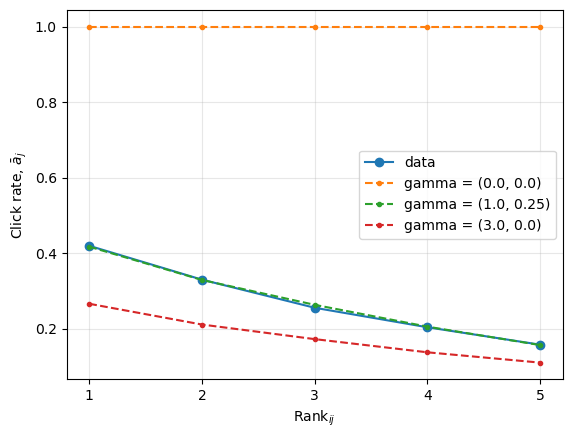

In [9]:
rank_grid = np.arange(1, J + 1)
for col in implied.columns:
    click_rates = implied.loc[[f'clicked at {j}' for j in rank_grid], col]
    plt.plot(rank_grid, click_rates.values, 'o-' if col == 'data' else '.--', label=col)
plt.xlabel(r'$\mathrm{Rank}_{ij}$')
plt.ylabel(r'Click rate, $\bar a_j$')
plt.xticks(rank_grid)
plt.legend()
plt.grid(alpha=0.3);

Discussion: the booking rates agree across the three, and with the data, up to simulation noise: in the model they are identical. The searches are not. At $\gamma = 0$ search is free, so everyone searches all five hotels. At $(3, 0)$ search is so costly that 18% search nothing, close to the 20% who buy nothing, and clicks fall with position only because purchases do. Only $(1, 0.25)$ comes close to the data.

# Q3: Estimating $\gamma$

For each $(\gamma_0, \gamma_{\text{pos}})$ on the grid, compute $Q(\gamma \mid \hat\theta)$, eq. (3): set $\beta = \hat\theta + \gamma$, simulate $R$ data sets, average the simulated search dummies into $\bar a_{ij}(\gamma)$, and average the squared differences from the data.

The draws are made once, here, and reused at every grid point, so $Q$ moves only because $\gamma$ does. Draw `r = 0` is the one Q2.b used.

In [10]:
R = 50
rng = np.random.default_rng(7)
eps_draws = [pd.Series(rng.gumbel(size=epsilon.size), epsilon.index) for r in range(R)] # eps_draws[0] is eps_model
a_data = searched_inside # a_ij, (N*J,)-vector, inside options only

def simulated_searches(delta, mu, eps, seed):
    '''a_ij^(r): one simulated search dummy for every consumer and inside option.'''
    d_, searched_ = simulate_search(delta, mu, eps, seed=seed)
    I_inside_ = searched_.index.get_level_values('j') > 0 # the outside option is always "searched"
    searched_ = searched_[I_inside_]
    return searched_

g0_grid = [0.5, 1.0, 1.5]
gp_grid = [0.15, 0.25, 0.35]

def grid_search(X_, theta_, a_data_, eps_draws_):
    '''Q(gamma | theta_), eq. (3), at every point on the grid, with one simulated data set per element of eps_draws_.'''
    rows = []
    for g0, gp in tqdm(list(product(g0_grid, gp_grid)), desc=f'grid, R = {len(eps_draws_)}'):
        gamma = gamma_from(g0, gp)
        beta = theta_ + gamma
        a_sim = [simulated_searches(X_ @ beta, X_ @ gamma, eps, seed=3 + r) for r, eps in enumerate(eps_draws_)]
        a_sim = pd.concat(a_sim, axis=1) # step 2: one column per replication r
        a_bar = a_sim.mean(axis=1)
        Q = ((a_data_ - a_bar) ** 2).mean()
        rows.append({'gamma_0': g0, 'gamma_pos': gp, 'Q': Q})
    return pd.DataFrame(rows)

In [11]:
tab_grid = grid_search(X, theta_hat, a_data, eps_draws)
tab_grid.pivot(index='gamma_0', columns='gamma_pos', values='Q').round(5)


grid, R = 50:   0%|          | 0/9 [00:00<?, ?it/s]


grid, R = 50:  11%|█         | 1/9 [00:02<00:21,  2.68s/it]


grid, R = 50:  22%|██▏       | 2/9 [00:05<00:19,  2.76s/it]


grid, R = 50:  33%|███▎      | 3/9 [00:08<00:17,  2.89s/it]


grid, R = 50:  44%|████▍     | 4/9 [00:11<00:14,  2.94s/it]


grid, R = 50:  56%|█████▌    | 5/9 [00:14<00:12,  3.02s/it]

... (2 outputs left out)


grid, R = 50:  89%|████████▉ | 8/9 [00:24<00:03,  3.19s/it]


grid, R = 50: 100%|██████████| 9/9 [00:27<00:00,  3.24s/it]


grid, R = 50: 100%|██████████| 9/9 [00:27<00:00,  3.09s/it]

gamma_pos,0.15,0.25,0.35
gamma_0,,,
0.5,0.22410,0.20173,0.19368
1.0,0.19305,0.19006,0.19061
1.5,0.19134,0.19296,0.19503


In [12]:
best = tab_grid.loc[tab_grid['Q'].idxmin()]
gamma_0_hat, gamma_pos_hat = best['gamma_0'], best['gamma_pos']
beta_hat_grid = theta_hat + gamma_from(gamma_0_hat, gamma_pos_hat)
beta_0_hat, beta_pos_hat = beta_hat_grid['constant'], beta_hat_grid['position']
print(f'gamma_0 = {gamma_0_hat:.2f} (true 1), gamma_pos = {gamma_pos_hat:.2f} (0.25), beta_0 = {beta_0_hat:.3f} (1.5), beta_pos = {beta_pos_hat:.3f} (-0.05)')

gamma_0 = 1.00 (true 1), gamma_pos = 0.25 (0.25), beta_0 = 1.473 (1.5), beta_pos = -0.044 (-0.05)


Discussion: the grid search finds the truth. How much consumers search overall pins down $\gamma_0$: a higher $\gamma_0$ makes every hotel costlier to search. How fast searching falls with position pins down $\gamma_{\text{pos}}$. The next-best points trade one against the other, a lower $\gamma_0$ with a higher $\gamma_{\text{pos}}$ or the reverse, which keeps the number of searches about right but gets the slope wrong.

# Q4: Position effects

## Q4.a: Causal effects and a prediction

Four lines against $\text{Rank}_{ij}$. Three are causal effects of moving a hotel down the list: on taste, $\hat\beta_0 + \hat\beta_{\text{pos}}\text{Rank}_{ij}$, on the search cost, $\hat\gamma_0 + \hat\gamma_{\text{pos}}\text{Rank}_{ij}$, and on $\delta_{ij} - \mu_{ij}$, $\hat\theta_0 + \hat\theta_{\text{pos}}\text{Rank}_{ij}$. The fourth is a prediction: the average of $\hat\delta_{ij} - \hat\mu_{ij} = \mathbf{x}_{ij}'\hat\theta$ over the hotels shown at each rank.

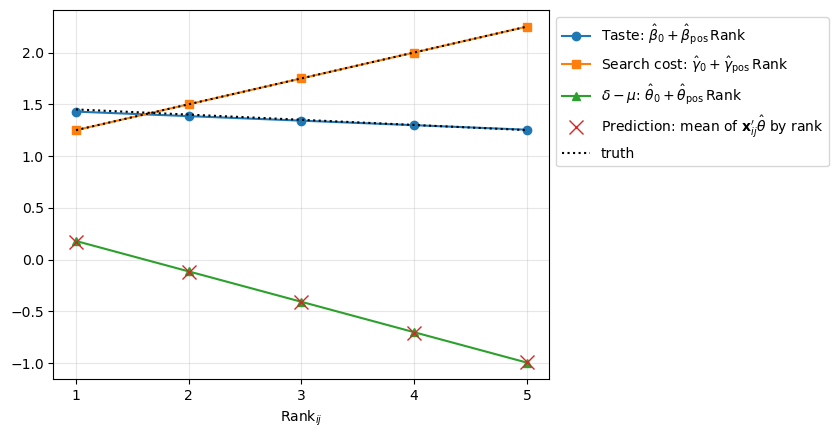

In [13]:
purchases_line = theta_hat['constant'] + theta_hat['position'] * rank_grid
search_cost_line = gamma_0_hat + gamma_pos_hat * rank_grid
taste_line = beta_0_hat + beta_pos_hat * rank_grid

v_hat = X @ theta_hat # x_ij' theta_hat = delta_ij - mu_ij, all that purchases give us
v_hat_inside = v_hat[I_inside]
rank_inside = position[I_inside]
mean_line = v_hat_inside.groupby(rank_inside).mean()

plt.plot(rank_grid, taste_line, 'o-', label=r'Taste: $\hat\beta_0 + \hat\beta_{\mathrm{pos}}\,\mathrm{Rank}$')
plt.plot(rank_grid, search_cost_line, 's-', label=r'Search cost: $\hat\gamma_0 + \hat\gamma_{\mathrm{pos}}\,\mathrm{Rank}$')
plt.plot(rank_grid, purchases_line, '^-', label=r'$\delta - \mu$: $\hat\theta_0 + \hat\theta_{\mathrm{pos}}\,\mathrm{Rank}$')
plt.plot(rank_grid, mean_line.values, 'x', ms=10, label=r'Prediction: mean of $\mathbf{x}_{ij}^\prime\hat\theta$ by rank')
plt.plot(rank_grid, beta_true[7] + beta_true[6] * rank_grid, ':k', label='truth')
plt.plot(rank_grid, gamma_true[1] + gamma_true[0] * rank_grid, ':k')
plt.xlabel(r'$\mathrm{Rank}_{ij}$')
plt.xticks(rank_grid)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1)) # outside the axes, clear of the lines
plt.grid(alpha=0.3);

Discussion: purchases fall steeply with position, and almost all of that is search cost. The search-cost line is steep and the taste line is nearly flat. The prediction sits on top of the $\hat\theta$ line, because in these data the hotels are shown in random order: the attributes at each rank are the same on average, so the average of $\mathbf{x}_{ij}'\hat\theta$ at a rank differs from the causal line only by the average attribute term, which is close to zero. Under Expedia's own ranking the best hotels go on top, so the prediction falls faster than the causal line: it mixes the effect of the position with the hotels the platform puts there. The random-ranking arm in Part B is what lets you read position effects causally.

## Q4.b: Two policies for the platform

Reproduce the table in Q4(b) of `ps9.pdf`, at each of the three $(\hat\beta(\gamma), \gamma)$ from Q2. Bookings and consumer surplus follow from the logit, because purchases are a logit in $\delta_{ij} - \mu_{ij} = \mathbf{x}_{ij}'\hat\theta$. Searches have to be simulated.

The re-sorting for best first is done for you. A row of `X` is a hotel, $(i, j)$, and it stays that hotel: re-sorting changes its `position`, $\text{Rank}_{ij}$, and nothing else. The new rank is the hotel's place when consumer $i$'s hotels are sorted, best first, by $\mathbf{x}_{ij}'\hat\theta - \hat\theta_{\text{pos}}\text{Rank}_{ij}$: the part of $\delta_{ij} - \mu_{ij}$ that the hotel brings with it, wherever it is shown. Since $\delta_{ij} - \mu_{ij} = \mathbf{x}_{ij}'\hat\theta$, each hotel's $\delta_{ij} - \mu_{ij}$ changes by $\hat\theta_{\text{pos}}\big(\text{Rank}_{ij}^{\text{new}} - \text{Rank}_{ij}^{\text{old}}\big)$.

In [14]:
def logsum(v):
    '''Consumer surplus by consumer, up to a constant. v is an (N*(J+1),)-vector of delta_ij - mu_ij.'''
    return np.log(np.exp(v).groupby(level='i').sum())

def booked(v):
    '''The share who buy an inside option. The outside row of v supplies the "1 +".'''
    return 1 - (1 / np.exp(v).groupby(level='i').sum()).mean()

In [15]:
# compute the variable to rank on: x_ij' theta_hat without the position term
attributes = v_hat - theta_hat['position'] * position # (N*(J+1),)-vector
attributes = attributes[I_inside] # (N*J,)-vector, inside options only

# order within i by the variable: 1 = best attributes
rank_new = attributes.groupby('i').rank(ascending=False) # (N*J,)-vector, indexed by (i, j)

# re-order the rows of X accordingly and compute utilities of that order
rank = position.copy() # Rank_ij as it is, 0 for the outside option
rank[I_inside] = rank_new # pandas matches rows by their (i, j) index, so each hotel gets its own new rank
X_best = X.assign(position=rank) # the same hotels, re-sorted: only Rank_ij changes
v_best = X_best @ theta_hat # = v_hat + theta_pos * (Rank_new - Rank_old)

In [16]:
def answers(g):
    '''What the model says at (beta_hat(gamma), gamma).'''
    beta, gamma = beta_hat[g], gamma_from(*g)

    delta = X @ beta # free search: consumers choose on delta alone
    d_free, searched_free = simulate_search(delta, 0 * delta, eps_model, seed=3)
    searched_free = searched_free[I_inside]
    free_search = {'Free search: booked': booked(delta), 'Free search: CS gain': (logsum(delta) - logsum(v_hat)).mean(),
                   'Free search: searches': searched_free.sum() / d.size}

    d_best, searched_best = simulate_search(X_best @ beta, X_best @ gamma, eps_model, seed=3)
    searched_best = searched_best[I_inside]
    best_first = {'Best first: booked': booked(v_best), 'Best first: CS gain': (logsum(v_best) - logsum(v_hat)).mean(),
                  'Best first: searches': searched_best.sum() / d.size}

    return {'beta_0': beta['constant'], 'beta_pos': beta['position'], 'Booked': booked(v_hat), 'Searches': implied.loc['searches', f'gamma = {g}'], **best_first, **free_search}

In [17]:
%%time
counterfactuals = pd.DataFrame({f'gamma = {g}': answers(g) for g in gammas}).T
counterfactuals.round(3)

CPU times: user 177 ms, sys: 25.1 ms, total: 202 ms
Wall time: 201 ms


,beta_0,beta_pos,Booked,Searches,Best first: booked,Best first: CS gain,Best first: searches,Free search: booked,Free search: CS gain,Free search: searches
"gamma = (0.0, 0.0)",0.473,-0.294,0.8,5.000,0.826,0.141,5.000,0.800,0.000,5.0
"gamma = (1.0, 0.25)",1.473,-0.044,0.8,1.373,0.826,0.141,1.386,0.955,1.494,5.0
"gamma = (3.0, 0.0)",3.473,-0.294,0.8,0.899,0.826,0.141,0.932,0.987,2.787,5.0


Discussion: (c) Best first raises bookings from 0.800 to 0.826 and consumer surplus by 0.141. Free search does far more at the estimated $\gamma$: bookings rise to 0.955 and consumer surplus by 1.49. (d) Under free search everyone searches all five hotels. Under best first the searches barely move, and how much depends on $\gamma$. Two forces pull against each other: more consumers book, and every booking is a search, but the hotels they end up buying now sit in the slots that are cheap to search, so fewer searches are wasted. At $\gamma = (3, 0)$ every slot costs the same to search, so only the first force is at work. (e) Bookings and consumer surplus depend only on $\delta_{ij} - \mu_{ij}$, and consumer surplus is the logsum of it. Best first moves each hotel's $\delta_{ij} - \mu_{ij}$ by $\hat\theta_{\text{pos}}(\text{Rank}_{ij}^{\text{new}} - \text{Rank}_{ij}^{\text{old}})$, which purchases alone pin down, so its bookings and welfare are the same in every row, whatever $\gamma$ we assumed. Free search sets $\mu_{ij} = 0$, so it raises each $\delta_{ij} - \mu_{ij}$ by $\mu_{ij}$, and that needs $\gamma$: the welfare gain moves almost one for one with $\gamma_0$. The number of searches needs $\gamma$ under both policies, because it depends on $\delta_{ij}$ and $\mu_{ij}$ separately. So the platform can learn what best first does to bookings and welfare from purchases alone, but not what free search does.

# Q5: Selection on search

Expedia records no session without a click. Do the same to the data: drop the consumers who search nothing.

In [18]:
# find the rows (i, j) where i searched at least one inside option
I_keep = n_searched > 0 # (N,)-vector, by consumer
idx_keep = n_searched.index[I_keep]
I_sel = df_utility.index.get_level_values('i').isin(idx_keep) # (N*(J+1),)-vector, by (i, j), outside option included

# subsample the data
X_sel, I_chosen_sel = X[I_sel], I_chosen[I_sel]

# estimate theta on the subsample
res_sel = minimize(loglike, np.zeros(len(beta_labels)), args=(X_sel, I_chosen_sel, gamma_from(0.0, 0.0)), method='BFGS')
theta_sel = pd.Series(res_sel.x, beta_labels)
pd.DataFrame({'All consumers': theta_hat, 'At least one click': theta_sel}).T.round(3)

,price,stars,review,chain,location,promotion,position,constant
All consumers,-0.300,0.376,-0.259,0.002,-0.148,0.161,-0.294,0.473
At least one click,-0.304,0.376,-0.259,0.003,-0.149,0.163,-0.294,1.122


Now the second step, the grid search of Q3, on the same selected consumers, as if nobody were missing. Nothing is selected on purchases: we keep exactly the consumers above, and, as in Q3, compare only the inside options, because the outside option is always "searched".

In [19]:
%%time
# the search data of the selected consumers, inside options only, as a_data in Q3
I_sel_inside = I_sel & I_inside # (N*(J+1),)-vector, by (i, j)
a_data_sel = searched[I_sel_inside]

# the same draws as in Q3, for the selected consumers only
eps_draws_sel = [eps[I_sel] for eps in eps_draws]

# the grid search, with theta_hat from the selected consumers
tab_sel = grid_search(X_sel, theta_sel, a_data_sel, eps_draws_sel)
best_sel = tab_sel.loc[tab_sel['Q'].idxmin()]


grid, R = 50:   0%|          | 0/9 [00:00<?, ?it/s]


grid, R = 50:  11%|█         | 1/9 [00:02<00:19,  2.38s/it]


grid, R = 50:  22%|██▏       | 2/9 [00:05<00:17,  2.53s/it]


grid, R = 50:  33%|███▎      | 3/9 [00:07<00:15,  2.63s/it]


grid, R = 50:  44%|████▍     | 4/9 [00:10<00:13,  2.68s/it]


grid, R = 50:  56%|█████▌    | 5/9 [00:13<00:11,  2.77s/it]

... (2 outputs left out)


grid, R = 50:  89%|████████▉ | 8/9 [00:22<00:02,  2.97s/it]


grid, R = 50: 100%|██████████| 9/9 [00:25<00:00,  3.00s/it]


grid, R = 50: 100%|██████████| 9/9 [00:25<00:00,  2.85s/it]

CPU times: user 23.2 s, sys: 2.04 s, total: 25.3 s
Wall time: 25.6 s


In [20]:
pd.DataFrame({
    'Truth': {'gamma_0': 1.0, 'gamma_pos': 0.25, 'beta_0': 1.5, 'beta_pos': -0.05},
    'All consumers, Q3': {'gamma_0': gamma_0_hat, 'gamma_pos': gamma_pos_hat, 'beta_0': beta_0_hat, 'beta_pos': beta_pos_hat},
    'At least one click': {'gamma_0': best_sel['gamma_0'], 'gamma_pos': best_sel['gamma_pos'],
                           'beta_0': theta_sel['constant'] + best_sel['gamma_0'], 'beta_pos': theta_sel['position'] + best_sel['gamma_pos']},
}).T.round(3)

,gamma_0,gamma_pos,beta_0,beta_pos
Truth,1.0,0.25,1.500,-0.050
"All consumers, Q3",1.0,0.25,1.473,-0.044
At least one click,1.0,0.25,2.122,-0.044


Discussion: the slopes of the logit do not move, but its constant does, from about 0.5 to about 1.1, because the consumers who are left are the ones more likely to buy. The bias lands on taste: $\hat\beta_0 = \hat\theta_0 + \hat\gamma_0$ comes out at about 2.1, against a true 1.5. On this grid $\hat\gamma$ does not move, because two errors offset. The data search more than the full population does, since the consumers who searched nothing are gone, and the simulated consumers search more too, since the inflated constant makes every hotel look better. Selection does not show up in the search estimates here, but it is still there: every taste-side answer, such as the gain from free search, inherits the inflated $\hat\beta_0$.

# Q6$^*$ (optional): Search probabilities, computed

This question is optional, and nothing later in the course requires it. Instead of counting simulated searches, we compute the probability that consumer $i$ searches hotel $j$, eq. (5) in `ps9.pdf`.

## Q6$^*$.a: One hotel

With one hotel, the rival is the outside option, so $b_{i,-1} = 0$. Eq. (5) integrates against $dF^0(v - b_{i,-j})$, which is not something you can type into a computer. So we turn it into an ordinary integral. The T1EV density is
$$f^0(x) = e^{-x}\exp(-e^{-x}), \qquad \text{so that} \qquad dF^0(v - b_{i,-j}) = f^0(v - b_{i,-j})\,dv,$$
and eq. (5) becomes eq. (6):
$$\Pr(i \text{ searches } j) = \int_{-\infty}^{\infty} g(v)\,dv, \qquad g(v) \equiv \frac{1-F^0(v-\delta_{ij}+\mu_{ij})}{1-F^0(v-\delta_{ij})}\, f^0(v - b_{i,-j}).$$
A *quadrature rule* replaces the integral by a weighted sum over nodes $v_1, \dots, v_K$:
$$\int_{-\infty}^{\infty} g(v)\,dv \approx \sum_{k=1}^{K} w_k\, g(v_k).$$
The simplest rule puts the nodes a distance $h$ apart and sets every weight to $w_k = h$. That adds up the areas of $K$ thin rectangles, each $h$ wide and $g(v_k)$ tall. Since $f^0(v - b_{i,-j})$ is negligible outside $[b_{i,-j} - 10,\ b_{i,-j} + 40]$, nodes on that interval are enough. In code, $1 - F^0$ is `gumbel_r.sf` and $f^0$ is `gumbel_r.pdf`.

In [21]:
def pr_search_sum(delta, mu, b=0.0, h=0.05):
    '''Pr(i searches j) as the sum in eq. (6). delta, mu and b are scalars.'''
    v = np.arange(b - 10, b + 40, h) # the nodes
    g = gumbel_r.sf(v - delta + mu) / gumbel_r.sf(v - delta) * gumbel_r.pdf(v - b)
    return h * g.sum()

The closed form is eq. (7), with `scipy.special.digamma`.

In [22]:
def pr_search(s, mu):
    '''Pr(i searches j) in closed form, eq. (7). s is the option's purchase probability
    and mu its search cost shifter. Works on scalars, arrays and Series.'''
    a = s / (1 - s) # the odds of buying
    A = a * np.exp(mu)
    prob = (digamma((1 + a) / A) - digamma(1 / A)) / A
    return prob

In [23]:
# check that the two agree. With one hotel, s is the logit in delta - mu
for this_delta, this_mu in [(np.log(2), np.log(2)), (np.log(4), np.log(4)), (1.5, 1.25)]:
    s = np.exp(this_delta - this_mu) / (1 + np.exp(this_delta - this_mu))
    print(f'delta = {this_delta:.3f}, mu = {this_mu:.3f}: Sum: {pr_search_sum(this_delta, this_mu):.6f}, Closed form: {pr_search(s, this_mu):.6f}')

delta = 0.693, mu = 0.693: Sum: 0.693147, Closed form: 0.693147
delta = 1.386, mu = 1.386: Sum: 0.565986, Closed form: 0.565986
delta = 1.500, mu = 1.250: Sum: 0.630359, Closed form: 0.630359


## Q6$^*$.b: Five hotels, against the click rates

Now the rival of hotel $j$ is the best index among the outside option and the other hotels. Eq. (7) needs the purchase probabilities $s_{ij}$ of eq. (1).

In [24]:
def purchase_probs(v):
    '''Logit purchase probabilities by (i, j), eq. (1), with v_ij = delta_ij - mu_ij. The outside row of `v` supplies the "1 +".'''
    e = np.exp(v)
    s = e / e.groupby(level='i').transform('sum')
    return s

In [25]:
s_true = purchase_probs(delta_true - mu_true)
search_true = pr_search(s_true, mu_true)
search_true_inside = search_true[I_inside]
computed = search_true_inside.groupby(level='j').mean()
pd.DataFrame({'Simulated (the data)': clicks, 'Computed': computed}).T.round(4)

j,1,2,3,4,5
Simulated (the data),0.4198,0.3301,0.2557,0.2041,0.1580
Computed,0.4199,0.3307,0.2582,0.2005,0.1554


In [26]:
# is the gap to the data sampling noise? Eight fresh simulations with the same covariates
reps = []
for r_ in range(8):
    eps_r = pd.Series(np.random.default_rng(100 + r_).gumbel(size=epsilon.size), epsilon.index)
    searched_r = simulate_search(delta_true, mu_true, eps_r, seed=200 + r_)[1]
    searched_r = searched_r[I_inside]
    reps.append(searched_r.groupby(level='j').mean().values)
reps = np.array(reps)
print('Eight fresh simulations, mean:', reps.mean(0).round(4))
print('Standard deviation:           ', reps.std(0, ddof=1).round(4))
print('Computed:                     ', computed.values.round(4))

Eight fresh simulations, mean: [0.4196 0.3296 0.2578 0.201  0.1547]
Standard deviation:            [0.0042 0.0063 0.0026 0.0057 0.0027]
Computed:                      [0.4199 0.3307 0.2582 0.2005 0.1554]


Discussion: the computed rates match the simulated ones up to sampling noise. The other hotels' search costs enter only through $b_{i,-j}$, and only together with their $\delta_{ik}$, as $\delta_{ik} - \mu_{ik}$. So they are already inside $s_{ij}$: the odds of buying $j$ are $\exp(\delta_{ij} - \mu_{ij} - b_{i,-j})$.